In [267]:
import pandas as pd   
import numpy as np       
import matplotlib.pyplot as plt 
from pathlib import Path 
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

In [268]:
# load data 
BASE_DIR = Path().cwd()
DATA_DIR = BASE_DIR / "temp_data.csv"

if not DATA_DIR.exists():
    raise FileExistsError("Data Doesn't exist")
if not DATA_DIR.suffix in [".csv", ".xlsx"]:
    raise TypeError("Expected File Type Missing")

df = pd.read_csv(DATA_DIR)

if df.empty:
    raise ValueError("Loaded Dataframe is Empty")
if len(set(df.columns)) != len(df.columns):
    print("Data has duplicated columns\n"
          "Dropping Duplicate Columns ...")
    df = df.loc[:, df.columns.drop_duplicates()]  
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

for col in [col for col in df.columns if "date" in col]:
    df[col] = pd.to_datetime(df[col])
df = df.rename(columns={
     'date-time_(cst/cdt)': "datetime", 
     'temperature___(°f)': "temperature_f", 
     'rh___(%)': "relative_humidity",
       'dew_point___(°f)': "dew_point_f", 
    })

df = df.drop(columns=["#", "host_connected", "end_of_file"])
if "datetime" not in df.columns:
    df = df.apply(pd.to_numeric, errors="coerce")

df = df.dropna()

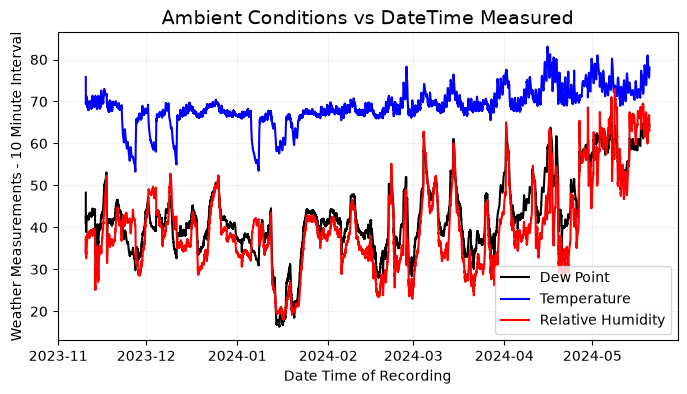

In [269]:
plt.figure(figsize=(8,4))
plt.plot(df["datetime"], df["dew_point_f"], label="Dew Point", color="black")
plt.plot(df["datetime"], df["temperature_f"], label="Temperature", color="blue")
plt.plot(df["datetime"], df["relative_humidity"], label="Relative Humidity", color="red")
plt.grid(color="gray", alpha=0.1)
plt.xlabel("Date Time of Recording")
plt.ylabel("Weather Measurements - 10 Minute Interval")
plt.title("Ambient Conditions vs DateTime Measured", fontsize=14)
plt.legend()
plt.show()

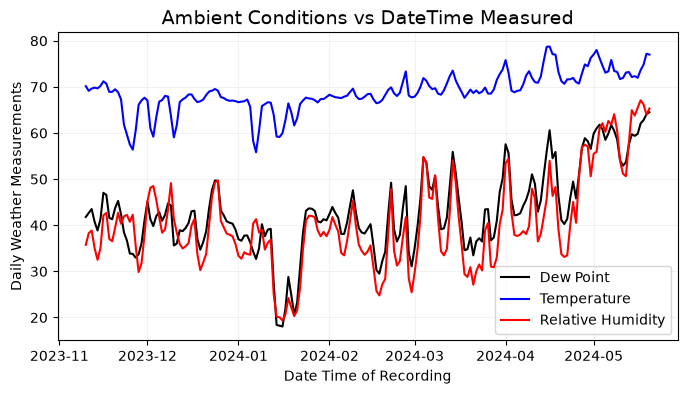

In [270]:
cols = ["temperature_f", "dew_point_f", "relative_humidity"]
dates = pd.to_datetime(df["datetime"], errors="raise").dt.normalize()
daily = (
    df.groupby(dates.rename("date"))[cols]
    .mean()
    .reset_index()
)
selected_cols = ["date","temperature_f"]
new_data = daily.loc[:, selected_cols]

# Predict Data 
plt.figure(figsize=(8,4))
plt.plot(daily["date"], daily["dew_point_f"], label="Dew Point", color="black")
plt.plot(daily["date"], daily["temperature_f"], label="Temperature", color="blue")
plt.plot(daily["date"], daily["relative_humidity"], label="Relative Humidity", color="red")
plt.grid(color="gray", alpha=0.1)
plt.xlabel("Date Time of Recording")
plt.ylabel("Daily Weather Measurements")
plt.title("Ambient Conditions vs DateTime Measured", fontsize=14)
plt.legend()
plt.show()

In [ ]:
target = "temperature_f"
df_model = new_data.copy()

df_model[target] = pd.to_numeric(df_model[target], errors="coerce")
season_by_month = {
    11: "fall",
    12: "winter",
    1: "winter",
    2: "winter",
    3: "spring",
    4: "spring",
    5: "spring",
        }

df_model["season"] = df_model["month"].map(season_by_month).rename("season")
winter = df_model[df_model["season"] == "winter"] 

if df_model.empty or df_model["date"].isna().any():
    raise ValueError("Expected an leas one row or valid date for every row.")
if df_model["date"].duplicated().any():
    raise ValueError("Expected One Temperature per Day")

temperature = df_model.set_index("date")[target].sort_index().asfreq("D")
def build_features(temperature):
    """ build features for training """
    X = pd.DataFrame(index=temperature.index)
    for lag in [1, 2, 3, 7, 14, 30]:
        X[f"temp_lag_{lag}"] = temperature.shift(lag)
        
    calendar_features = ['day','month']
    for feature in calendar_features:
        X[feature] = getattr(X.index, feature)
        
    past = temperature.shift(1)
    X["temp_mean_3d"] = past.rolling(3).mean()
    X["temp_mean_7d"] = past.rolling(7).mean()
    X["temp_change_1d"] = X["temp_lag_1"] - X["temp_lag_2"]
    
    angle = 2 * np.pi * (X.index.dayofyear - 1) / 365.25
    X["annual_sin"] = np.sin(angle)
    X["annual_cos"] = np.cos(angle)
    return X
    
X = build_features(temperature)
y = temperature

# Use the same dates for both models. Persistence needs yesterday's reading.
scorable = y.notna() & X["temp_lag_1"].notna()

C:\Users\Owner\AppData\Local\Temp\ipykernel_34080\2751758156.py:27: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * (X.index.dayofyear - 1) / 365.25


In [280]:
season_by_month = {
    11: "fall",
    12: "winter",
    1: "winter",
    2: "winter",
    3: "spring",
    4: "spring",
    5: "spring",
        }

X["season"] = X["month"].map(season_by_month).rename("season")

{'MAE': 3.0, 'R-squared': -1.39, 'RMSE': 3.65}


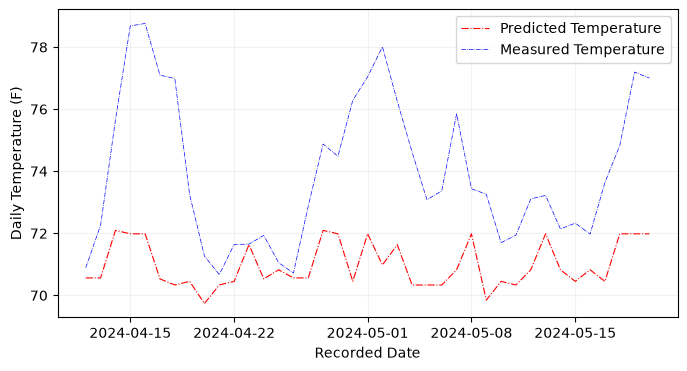

In [275]:
# build timeseries model without back testing 
model = XGBRegressor(
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    random_state=42,
)
pipe = Pipeline([("model", model)])

data_splits = int(len(X) * 0.8)
X_train, X_test = X.iloc[:data_splits], X.iloc[data_splits:]
y_train, y_test = y.iloc[:data_splits], y.iloc[data_splits:]

cloned_pipe = clone(pipe)
cloned_pipe.fit(X_train, y_train)
y_predict = cloned_pipe.predict(X_test)

summary_results = {"MAE": round(mean_absolute_error(y_test, y_predict),2),
                    "R-squared": round(r2_score(y_test, y_predict), 2),
                    "RMSE": round(root_mean_squared_error(y_test, y_predict),2),
                        }
print(summary_results)

plt.figure(figsize=(8,4))
plt.plot(X_test.index, y_predict, color="red", label="Predicted Temperature", linewidth=0.8, linestyle="-.")
plt.plot(X_test.index, y_test, color="blue", label="Measured Temperature", linewidth=0.5, linestyle="-.")
plt.xlabel("Recorded Date")
plt.ylabel("Daily Temperature (F)")
plt.grid(color="gray", alpha=0.1,)
plt.legend()
plt.show()

In [276]:
print(pd.DataFrame({
    "train": y_train.describe(),
    "holdout": y_test.describe(),
}).round(2))

print("Holdout days warmer than any training day:",
      (y_test > y_train.max()).sum())

        train  holdout
count  154.00    39.00
mean    67.55    73.98
std      3.45     2.39
min     55.82    70.67
25%     66.89    71.96
50%     67.96    73.26
75%     69.26    76.05
max     75.81    78.76
Holdout days warmer than any training day: 11


In [273]:
model = XGBRegressor(
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    random_state=42,
)
pipe = Pipeline([("model", model)])

holdout_days = 28
fold_days = 28
n_splits = 3

dev_dates = X.index[:-holdout_days]
holdout_dates = X.index[-holdout_days:]

if len(dev_dates) <= n_splits * fold_days:
    raise ValueError("Use shorter validation blocks or supply more daily history.")

def score_block(train_dates, test_dates):
    """ """
    train_dates = train_dates[scorable.loc[train_dates].to_numpy()]
    scored_dates = test_dates[scorable.loc[test_dates].to_numpy()]

    if len(train_dates) == 0 or len(scored_dates) == 0:
        raise ValueError("This block has no usable training or test dates.")

    fitted_pipe = clone(pipe)
    fitted_pipe.fit(X.loc[train_dates], y.loc[train_dates])

    actual = y.loc[scored_dates]
    predictions = fitted_pipe.predict(X.loc[scored_dates])
    baseline = X.loc[scored_dates, "temp_lag_1"]

    return {
        "test_start": test_dates[0].date(),
        "test_end": test_dates[-1].date(),
        "train_days": len(train_dates),
        "scored_days": len(scored_dates),
        "xgb_mae_f": mean_absolute_error(actual, predictions),
        "baseline_mae_f": mean_absolute_error(actual, baseline),
    }

cv = TimeSeriesSplit(n_splits=n_splits, test_size=fold_days)

backtest = pd.DataFrame([
    {"fold": fold, **score_block(dev_dates[train], dev_dates[test])}
    for fold, (train, test) in enumerate(cv.split(dev_dates), start=1)
])
print(backtest.round(2).to_string(index=False))

# Run after settling on your features and model settings.
holdout = pd.DataFrame([score_block(dev_dates, holdout_dates)])
print("\nFinal holdout")
print(holdout.round(2).to_string(index=False))

 fold test_start   test_end  train_days  scored_days  xgb_mae_f  baseline_mae_f
    1 2024-01-30 2024-02-26          80           28       0.69            0.63
    2 2024-02-27 2024-03-25         108           28       1.58            1.15
    3 2024-03-26 2024-04-22         136           28       2.55            1.41

Final holdout
test_start   test_end  train_days  scored_days  xgb_mae_f  baseline_mae_f
2024-04-23 2024-05-20         164           28       1.21            1.07


In [274]:
if pd.isna(temperature.iloc[-1]):
    raise ValueError("The latest day needs a temperature for this forecast.")

forecast_model = clone(pipe)
forecast_model.fit(X.loc[scorable], y.loc[scorable])

tomorrow = temperature.index[-1] + pd.DateOffset(days=1)
extended = temperature.reindex(temperature.index.append(
    pd.DatetimeIndex([tomorrow])
))
X_tomorrow = build_features(extended).loc[[tomorrow]]

forecast_f = forecast_model.predict(X_tomorrow)[0]
baseline_f = temperature.iloc[-1]

print(f"{tomorrow:%Y-%m-%d} forecast: {forecast_f:.2f}°F")
print(f"Persistence baseline: {baseline_f:.2f}°F")

2024-05-21 forecast: 75.23°F
Persistence baseline: 77.00°F


C:\Users\Owner\AppData\Local\Temp\ipykernel_34080\2751758156.py:27: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * (X.index.dayofyear - 1) / 365.25
